# Inferensi video dengan YOLO26

Notebook ini menjalankan checkpoint YOLO26 yang sudah tersedia pada video lokal. Pilih varian `n`, `s`, `m`, `l`, atau `x`, lalu atur daftar path model dan path video pada cell konfigurasi.

Hasil inferensi disimpan sebagai video beranotasi dan `detections.csv` di folder `runs/inference/`. Inferensi memakai streaming agar semua frame tidak ditampung sekaligus di memori.

**Urutan penggunaan:** jalankan cell dari atas ke bawah. Gunakan kernel `.venv-training`, sesuai metadata notebook, dengan dependency dari `requirements-training.txt`.

## 1. Konfigurasi video dan varian model

Urutan path pada `MODEL_PATHS` menentukan prioritas. Path dengan `*` otomatis mencakup folder run, misalnya `enemy-yolo26s-3`. Tambahkan path checkpoint lain di daftar varian yang akan digunakan. Ambang confidence minimal adalah 0.50; deteksi di bawah nilai ini tidak diteruskan. Nama folder output menyertakan nilai ambang agar hasil dengan confidence berbeda tersimpan terpisah.

Output yang tersimpan dari eksekusi sebelumnya tidak berubah otomatis. Jalankan ulang cell inferensi dan ringkasan untuk menghasilkan hasil dengan ambang baru.


In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

# Varian checkpoint: n, s, m, l, atau x.
MODEL_VARIANT = "n"

# Path pertama yang ditemukan akan dipakai. Sesuaikan atau tambahkan path untuk tiap varian.
# Path best.pt dari run training dicari lebih dahulu, kemudian last.pt dan bobot dasar lokal.
MODEL_PATHS = {
    "n": [
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26n*" / "weights" / "best.pt",
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26n*" / "weights" / "last.pt",
        PROJECT_ROOT / "weights" / "yolo26n.pt",
        PROJECT_ROOT / "yolo26n.pt",
    ],
    "s": [
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26s*" / "weights" / "best.pt",
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26s*" / "weights" / "last.pt",
        PROJECT_ROOT / "weights" / "yolo26s.pt",
        PROJECT_ROOT / "yolo26s.pt",
    ],
    "m": [
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26m*" / "weights" / "best.pt",
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26m*" / "weights" / "last.pt",
        PROJECT_ROOT / "weights" / "yolo26m.pt",
        PROJECT_ROOT / "yolo26m.pt",
    ],
    "l": [
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26l*" / "weights" / "best.pt",
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26l*" / "weights" / "last.pt",
        PROJECT_ROOT / "weights" / "yolo26l.pt",
        PROJECT_ROOT / "yolo26l.pt",
    ],
    "x": [
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26x*" / "weights" / "best.pt",
        PROJECT_ROOT / "runs" / "train" / "enemy-yolo26x*" / "weights" / "last.pt",
        PROJECT_ROOT / "weights" / "yolo26x.pt",
        PROJECT_ROOT / "yolo26x.pt",
    ],
}

# Ganti dengan path video lokal Anda. Path relatif dihitung dari folder proyek.
VIDEO_PATH = Path("video_testing") / "DJI_20260630134848_0004_D.MP4"
if not VIDEO_PATH.is_absolute():
    VIDEO_PATH = (PROJECT_ROOT / VIDEO_PATH).resolve()
else:
    VIDEO_PATH = VIDEO_PATH.expanduser().resolve()

# Nilai inferensi.
CONF_THRESHOLD = 0.50
IOU_THRESHOLD = 0.45
IMAGE_SIZE = 640
VIDEO_STRIDE = 1  # 1 = proses semua frame; 2 = lewati satu frame di antara frame yang diproses.
DEVICE_OVERRIDE = None  # None = gunakan GPU bila tersedia, selain itu CPU. Contoh: 0 atau "cpu".
PREVIEW_MAX_FRAMES = 6
PREVIEW_INTERVAL_SECONDS = 1.0

OUTPUT_ROOT = PROJECT_ROOT / "runs" / "inference"

if MODEL_VARIANT not in MODEL_PATHS:
    raise ValueError(f"MODEL_VARIANT harus salah satu dari {sorted(MODEL_PATHS)}")
if VIDEO_STRIDE < 1:
    raise ValueError("VIDEO_STRIDE minimal 1")
if not 0.50 <= CONF_THRESHOLD < 1.0:
    raise ValueError("CONF_THRESHOLD harus 0.50 atau lebih dan kurang dari 1.0")

print(f"Project: {PROJECT_ROOT}")
print(f"Varian: YOLO26{MODEL_VARIANT}")
print(f"Video: {VIDEO_PATH}")
print(f"Ukuran inferensi: {IMAGE_SIZE}px; ambang confidence: {CONF_THRESHOLD:.0%}")


Project: F:\Telkom  x Machung\uav_enemy_detection_pt1
Varian: YOLO26n
Video: F:\Telkom  x Machung\uav_enemy_detection_pt1\video_testing\DJI_20260630134848_0004_D.MP4
Ukuran inferensi: 640px; ambang confidence: 50%


## 2. Muat checkpoint dan periksa video

Cell ini memilih checkpoint pertama yang tersedia untuk varian aktif, lalu membaca metadata video sebelum inference.


In [2]:
import glob
import math

import cv2
import torch
from ultralytics import YOLO


def resolve_model_path(variant):
    """Pilih path pertama yang ada; pola glob di daftar path didukung."""
    expanded_candidates = []
    for configured_path in MODEL_PATHS[variant]:
        candidate = Path(configured_path).expanduser()
        if not candidate.is_absolute():
            candidate = (PROJECT_ROOT / candidate).resolve()
        if glob.has_magic(str(candidate)):
            matches = [
                Path(match).resolve()
                for match in glob.glob(str(candidate))
                if Path(match).is_file()
            ]
            matches.sort(key=lambda path: path.stat().st_mtime, reverse=True)
            expanded_candidates.extend(matches)
        else:
            expanded_candidates.append(candidate.resolve())

    seen = set()
    unique_candidates = []
    for candidate in expanded_candidates:
        key = str(candidate).casefold()
        if key not in seen:
            seen.add(key)
            unique_candidates.append(candidate)

    for candidate in unique_candidates:
        if candidate.is_file():
            return candidate, unique_candidates
    checked_paths = "\n".join(f"  - {candidate}" for candidate in unique_candidates)
    raise FileNotFoundError(
        f"Checkpoint untuk varian YOLO26{variant} tidak ditemukan.\n"
        "Tambahkan lokasi checkpoint yang benar pada MODEL_PATHS. Path yang diperiksa:\n"
        f"{checked_paths}"
    )


MODEL_PATH, _ = resolve_model_path(MODEL_VARIANT)
if not VIDEO_PATH.is_file():
    raise FileNotFoundError(
        f"Video tidak ditemukan: {VIDEO_PATH}\n"
        "Ubah VIDEO_PATH pada cell konfigurasi ke path file video yang tersedia."
    )

VIDEO_SUFFIXES = {".mp4", ".avi", ".mov", ".mkv", ".m4v", ".webm", ".mpg", ".mpeg"}
if VIDEO_PATH.suffix.lower() not in VIDEO_SUFFIXES:
    raise ValueError(
        f"Format video {VIDEO_PATH.suffix!r} belum termasuk format "
        "yang didukung notebook ini."
    )

DEVICE = (
    DEVICE_OVERRIDE
    if DEVICE_OVERRIDE is not None
    else (0 if torch.cuda.is_available() else "cpu")
)
model = YOLO(str(MODEL_PATH))
model_names = model.names
if isinstance(model_names, dict):
    MODEL_CLASS_NAMES = {
        int(class_id): str(class_name)
        for class_id, class_name in model_names.items()
    }
else:
    MODEL_CLASS_NAMES = {
        class_id: str(class_name)
        for class_id, class_name in enumerate(model_names)
    }
if len(MODEL_CLASS_NAMES) != 2:
    raise ValueError(
        f"Checkpoint ini memiliki {len(MODEL_CLASS_NAMES)} kelas, "
        "sedangkan proyek mengharapkan 2 kelas (Bukan Musuh dan Musuh). "
        "Pilih checkpoint hasil training yang benar pada MODEL_PATHS."
    )

capture = cv2.VideoCapture(str(VIDEO_PATH))
if not capture.isOpened():
    capture.release()
    raise ValueError(f"OpenCV tidak dapat membuka video: {VIDEO_PATH}")
VIDEO_FPS = float(capture.get(cv2.CAP_PROP_FPS))
VIDEO_FRAME_COUNT = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
VIDEO_WIDTH = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
VIDEO_HEIGHT = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
capture.release()
if not math.isfinite(VIDEO_FPS) or VIDEO_FPS < 0:
    VIDEO_FPS = 0.0
VIDEO_DURATION_SECONDS = VIDEO_FRAME_COUNT / VIDEO_FPS if VIDEO_FPS > 0 else None

print(f"Checkpoint terpilih: {MODEL_PATH}")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Kelas pada checkpoint: {MODEL_CLASS_NAMES}")
print(f"Video: {VIDEO_WIDTH}x{VIDEO_HEIGHT}, {VIDEO_FPS:.3f} FPS, {VIDEO_FRAME_COUNT:,} frame")
if VIDEO_DURATION_SECONDS is not None:
    print(f"Durasi perkiraan: {VIDEO_DURATION_SECONDS:.1f} detik")


Checkpoint terpilih: F:\Telkom  x Machung\uav_enemy_detection_pt1\runs\train\enemy-yolo26n\weights\best.pt
Device: 0
GPU: NVIDIA GeForce RTX 5070
Kelas pada checkpoint: {0: 'Bukan Musuh (ally)', 1: 'Musuh (enemy)'}
Video: 1920x1080, 59.940 FPS, 4,510 frame
Durasi perkiraan: 75.2 detik


## 3. Jalankan inferensi video

Hasil gambar beranotasi ditulis Ultralytics ke subfolder `annotated_video`; tabel deteksi ditulis bertahap ke CSV agar penggunaan memori tetap stabil untuk video panjang.


In [3]:
import csv
import time
from collections import Counter
from decimal import Decimal

confidence_percent = Decimal(str(CONF_THRESHOLD)) * 100
if confidence_percent == confidence_percent.to_integral_value():
    confidence_suffix = f"{int(confidence_percent):02d}"
else:
    confidence_suffix = str(CONF_THRESHOLD).replace(".", "p")
VIDEO_RUN_NAME = f"{VIDEO_PATH.stem}_yolo26{MODEL_VARIANT}_conf{confidence_suffix}"
INFERENCE_DIR = OUTPUT_ROOT / VIDEO_RUN_NAME
ANNOTATED_VIDEO_DIR = INFERENCE_DIR / "annotated_video"
CSV_PATH = INFERENCE_DIR / "detections.csv"
INFERENCE_DIR.mkdir(parents=True, exist_ok=True)

csv_columns = [
    "frame_index",
    "time_seconds",
    "class_id",
    "class_name",
    "confidence",
    "x1",
    "y1",
    "x2",
    "y2",
]
class_detection_counts = Counter()
preview_frames = []
processed_frames = 0
detection_count = 0
preview_every_n_frames = max(
    1,
    round(VIDEO_FPS * PREVIEW_INTERVAL_SECONDS / VIDEO_STRIDE) if VIDEO_FPS > 0 else 1,
)

prediction_stream = model.predict(
    source=str(VIDEO_PATH),
    stream=True,
    save=True,
    project=str(INFERENCE_DIR),
    name="annotated_video",
    exist_ok=True,
    conf=CONF_THRESHOLD,  # hanya deteksi yang melewati ambang confidence ini yang diteruskan
    iou=IOU_THRESHOLD,
    imgsz=IMAGE_SIZE,
    device=DEVICE,
    vid_stride=VIDEO_STRIDE,
    batch=1,
    verbose=False,
)

started_at = time.perf_counter()
with CSV_PATH.open("w", encoding="utf-8-sig", newline="") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=csv_columns)
    writer.writeheader()

    for frame_index, result in enumerate(prediction_stream):
        processed_frames += 1
        frame_time = (frame_index * VIDEO_STRIDE / VIDEO_FPS) if VIDEO_FPS > 0 else ""
        boxes = result.boxes

        if boxes is None or len(boxes) == 0:
            writer.writerow({
                "frame_index": frame_index,
                "time_seconds": round(frame_time, 3) if frame_time != "" else "",
                "class_id": "",
                "class_name": "",
                "confidence": "",
                "x1": "", "y1": "", "x2": "", "y2": "",
            })
        else:
            coordinates = boxes.xyxy.detach().cpu().tolist()
            class_ids = boxes.cls.detach().cpu().int().tolist()
            confidences = boxes.conf.detach().cpu().tolist()
            for xyxy, class_id, confidence in zip(coordinates, class_ids, confidences):
                class_name = MODEL_CLASS_NAMES.get(class_id, f"Class {class_id}")
                class_detection_counts[class_id] += 1
                detection_count += 1
                writer.writerow({
                    "frame_index": frame_index,
                    "time_seconds": round(frame_time, 3) if frame_time != "" else "",
                    "class_id": class_id,
                    "class_name": class_name,
                    "confidence": round(float(confidence), 6),
                    "x1": round(float(xyxy[0]), 2),
                    "y1": round(float(xyxy[1]), 2),
                    "x2": round(float(xyxy[2]), 2),
                    "y2": round(float(xyxy[3]), 2),
                })

        if (
            len(preview_frames) < PREVIEW_MAX_FRAMES
            and frame_index % preview_every_n_frames == 0
        ):
            preview_frames.append((frame_index, result.plot(pil=True)))

elapsed_seconds = time.perf_counter() - started_at
print(f"Frame diproses: {processed_frames:,}")
print(f"Total deteksi: {detection_count:,}")
print(f"Waktu inferensi: {elapsed_seconds:.2f} detik")
if elapsed_seconds > 0:
    print(f"Kecepatan efektif: {processed_frames / elapsed_seconds:.2f} frame/detik")
print(f"CSV deteksi: {CSV_PATH}")
print(f"Folder video beranotasi: {ANNOTATED_VIDEO_DIR}")


Results saved to F:\Telkom  x Machung\uav_enemy_detection_pt1\runs\inference\DJI_20260630134848_0004_D_yolo26n_conf50\annotated_video
Frame diproses: 4,510
Total deteksi: 4,701
Waktu inferensi: 153.75 detik
Kecepatan efektif: 29.33 frame/detik
CSV deteksi: F:\Telkom  x Machung\uav_enemy_detection_pt1\runs\inference\DJI_20260630134848_0004_D_yolo26n_conf50\detections.csv
Folder video beranotasi: F:\Telkom  x Machung\uav_enemy_detection_pt1\runs\inference\DJI_20260630134848_0004_D_yolo26n_conf50\annotated_video


## 4. Ringkasan dan contoh frame

Tabel di bawah menghitung jumlah bounding box per kelas. Frame contoh berasal dari hasil inferensi yang sama dan ditampilkan setelah seluruh video selesai diproses.


Ringkasan deteksi per kelas:


,class_id,kelas,jumlah_deteksi
0,0,Bukan Musuh (ally),4438
1,1,Musuh (enemy),263


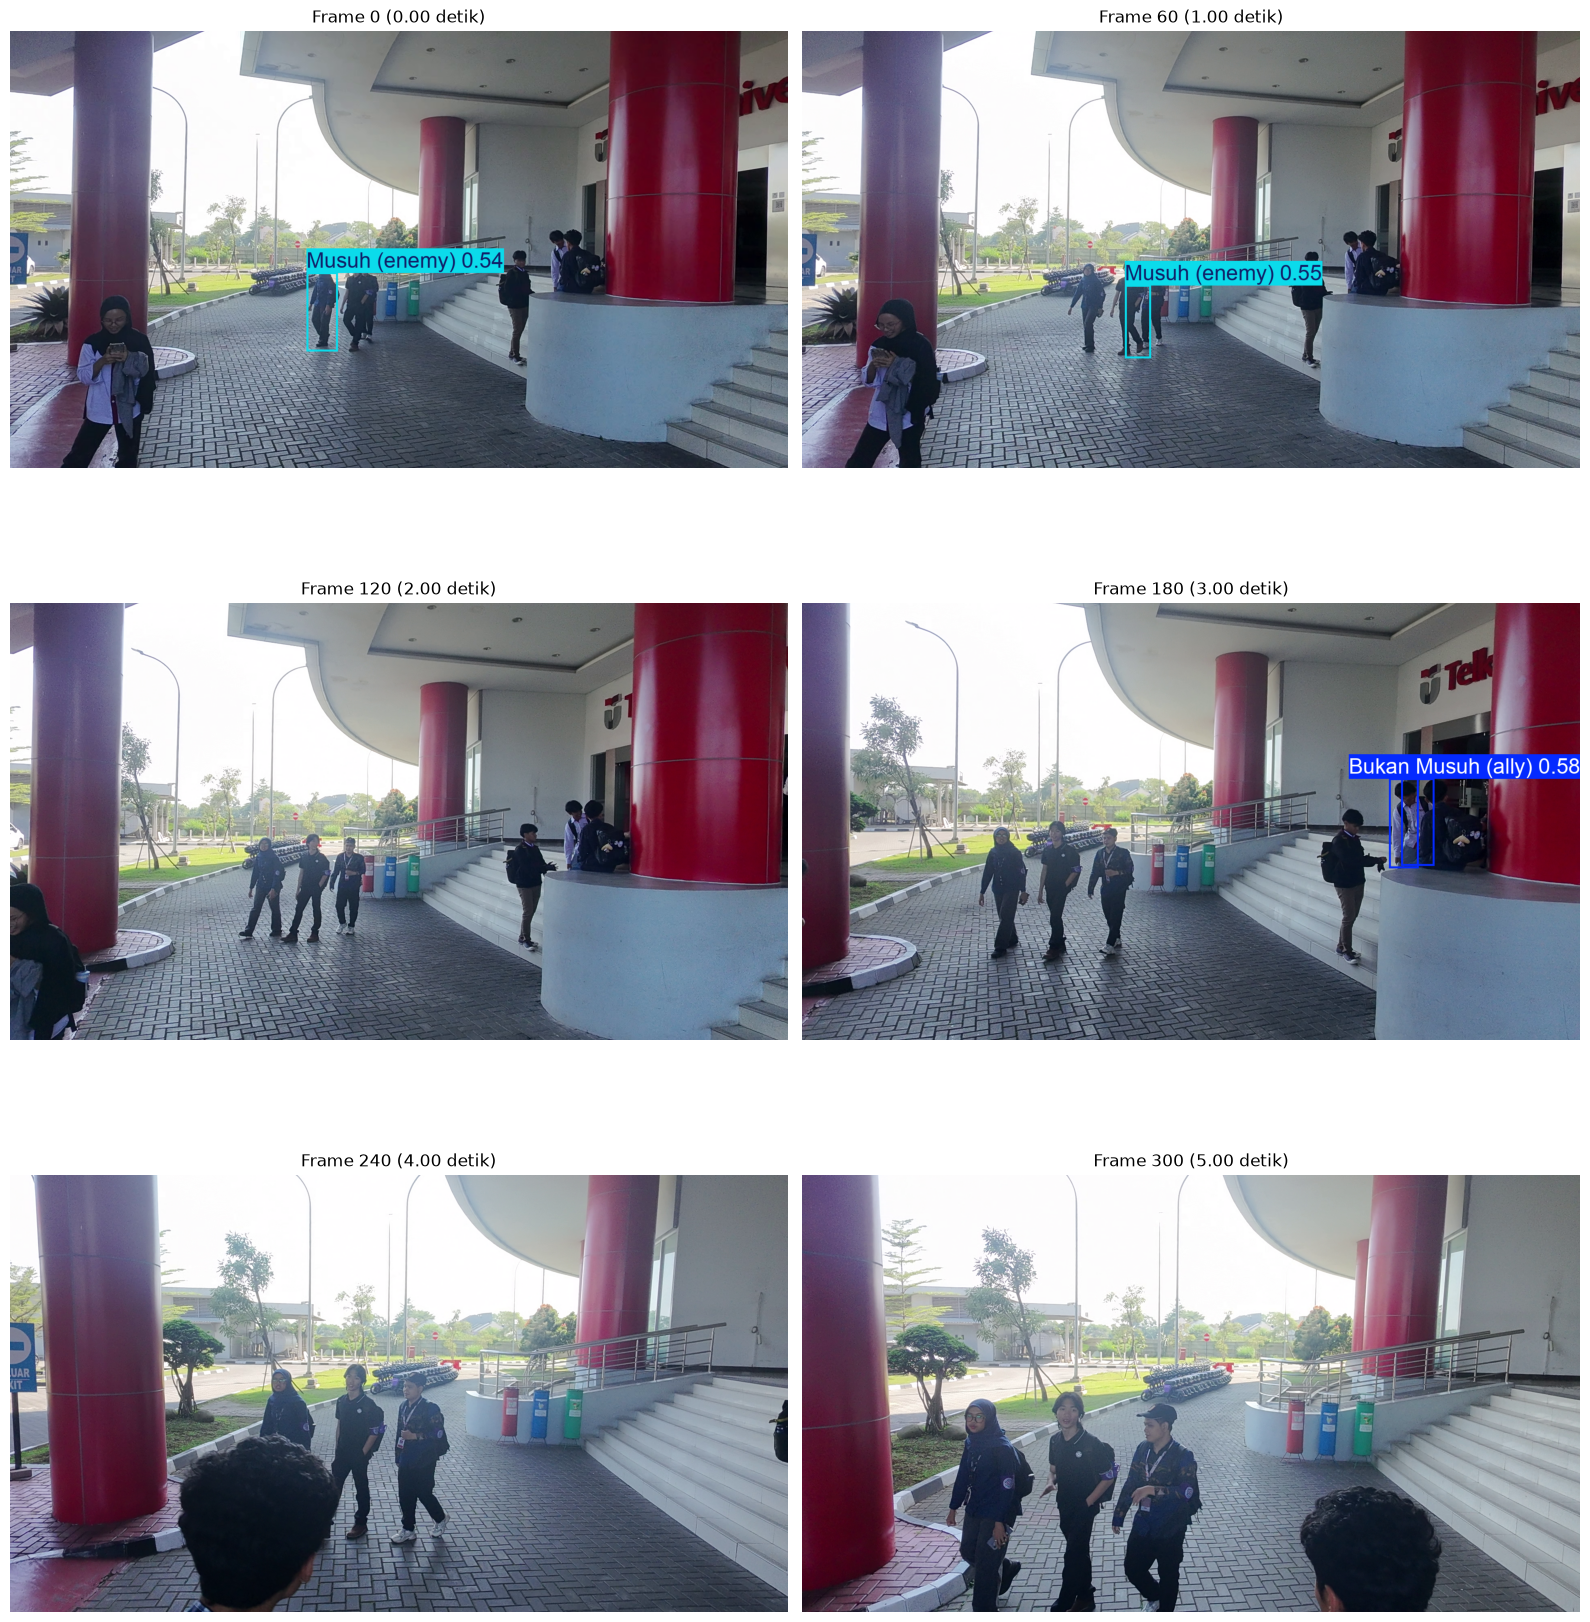

Video hasil:
  F:\Telkom  x Machung\uav_enemy_detection_pt1\runs\inference\DJI_20260630134848_0004_D_yolo26n_conf50\annotated_video\DJI_20260630134848_0004_D.avi


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

summary_rows = [
    {
        "class_id": class_id,
        "kelas": class_name,
        "jumlah_deteksi": class_detection_counts.get(class_id, 0),
    }
    for class_id, class_name in sorted(MODEL_CLASS_NAMES.items())
]
summary_df = pd.DataFrame(summary_rows)
print("Ringkasan deteksi per kelas:")
display(summary_df)

if not preview_frames:
    print("Tidak ada frame contoh untuk ditampilkan.")
else:
    columns = min(2, len(preview_frames))
    rows = (len(preview_frames) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(16, 6 * rows), squeeze=False)
    for axis, (frame_index, frame_image) in zip(axes.flat, preview_frames):
        axis.imshow(frame_image)
        timestamp = (frame_index * VIDEO_STRIDE / VIDEO_FPS) if VIDEO_FPS > 0 else None
        title = f"Frame {frame_index}"
        if timestamp is not None:
            title += f" ({timestamp:.2f} detik)"
        axis.set_title(title)
        axis.axis("off")
    for axis in list(axes.flat)[len(preview_frames):]:
        axis.axis("off")
    figure.tight_layout()
    plt.show()
    plt.close(figure)

saved_videos = sorted(
    path for path in ANNOTATED_VIDEO_DIR.glob("*")
    if path.is_file() and path.suffix.lower() in VIDEO_SUFFIXES
)
if saved_videos:
    print("Video hasil:")
    for saved_video in saved_videos:
        print(f"  {saved_video}")
else:
    print(
    "Belum menemukan file video hasil. Periksa log Ultralytics "
    "dan dukungan codec pada environment ini."
)


## Catatan

- Untuk mengganti model, ubah `MODEL_VARIANT` dan/atau urutan daftar pada `MODEL_PATHS` di cell pertama. Tiap varian dapat memiliki beberapa lokasi checkpoint.
- Path checkpoint training mengikuti nama run `enemy-yolo26{variant}` dari notebook training. Pola glob juga menemukan nama run dengan suffix otomatis.
- Untuk mengganti video, ubah `VIDEO_PATH` menjadi path file lokal yang benar. Path relatif dihitung dari root proyek.
- Output video, CSV, dan checkpoint notebook tersimpan di folder yang diabaikan Git. Notebook ini tidak mengunduh dataset atau melatih ulang model.